# Salario mediano anual en términos reales

In [ ]:
# Parámetros de la gráfica
SLUG = "empleo"  # carpeta en research/temas/
GRAFICA_ID = "salario-mediano-real"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Salario mediano anual en términos reales"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "solo_espana"  # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "Euros de 2015 al año (deflactado con el IPCA de España)"  # incluye deflactor/PPA si aplica (METODOLOGIA §2.4)
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 0  # decimales del CSV (el JSON guarda el valor completo)
REFERENCIA = None  # línea horizontal de referencia (p. ej. 100 en un índice); None = sin línea
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** El salario bruto anual mediano de los asalariados: el que separa la mitad que cobra más de la mitad que cobra menos, descontada la inflación (euros de 2015).

**Cómo se lee.** Un valor de 20.000 significa que la mitad de los asalariados ganó en el año menos de 20.000 euros brutos de 2015 y la otra mitad, más. A diferencia de la media, no lo mueven los salarios más altos.

**Limitaciones.**
- La encuesta cuenta a todos los asalariados que han estado de alta en la Seguridad Social al menos dos meses del año, uno de ellos octubre, y su ganancia de todo el año: incluye a quienes trabajan a tiempo parcial o solo parte del año, sin pasarlos a tiempo completo.
- No hay una mediana salarial anual comparable para la UE-27, la OCDE, EE. UU. y Canadá: Eurostat solo la publica cada cuatro años (Encuesta de Estructura Salarial), sin dato de la UE-27 en 2018 ni en 2022, y la OCDE solo publica medias. Por eso la gráfica es solo de España (`solo_espana`); el salario medio por asalariado a tiempo completo de la OCDE, con las cinco referencias, está en el notebook `salario-medio-real`.
- La vista por comunidades usa el mismo deflactor (el IPCA de España) para todas, así que compara salarios a precios de 2015 de España, no el poder de compra en cada comunidad.

## 2. Descarga

- **INE, Encuesta Anual de Estructura Salarial** (tabla 28191, «Medias y percentiles por sexo y CCAA»): mediana (`EAES738`) y media (`EAES741`, solo para las notas) de la ganancia bruta anual por trabajador, ambos sexos, total nacional; y la mediana de cada comunidad autónoma.
- **Eurostat, índice de precios de consumo armonizado** (`prc_hicp_aind`): índice general (`CP00`) de España, media anual, 2015 = 100.

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos, eurostat, ine
from lib.ccaa import NOMBRES_CCAA
from lib.tipos import FuenteMeta
from lib.writer import construir_grafica_data, construir_vista_ccaa, write_grafica_data

MEDIANA_ESPANA = "EAES738"
MEDIA_ESPANA = "EAES741"
# Mediana de cada comunidad (tabla 28191). El INE no publica Ceuta ni Melilla en esta tabla.
MEDIANA_CCAA = {
    "EAES732": "ES-AN", "EAES726": "ES-AR", "EAES720": "ES-AS", "EAES714": "ES-IB", "EAES708": "ES-CN",
    "EAES702": "ES-CB", "EAES696": "ES-CL", "EAES690": "ES-CM", "EAES684": "ES-CT", "EAES678": "ES-VC",
    "EAES672": "ES-EX", "EAES666": "ES-GA", "EAES660": "ES-MD", "EAES654": "ES-MC", "EAES648": "ES-NC",
    "EAES642": "ES-PV", "EAES636": "ES-RI",
}

nominal, f_nominal = ine.get({MEDIANA_ESPANA: "espana", MEDIA_ESPANA: "media"}, desde=DESDE)
nominal_ccaa, f_ccaa = ine.get(MEDIANA_CCAA, desde=DESDE)
ipca, _ = eurostat.get("prc_hicp_aind", {"freq": "A", "coicop": "CP00", "unit": "INX_A_AVG"}, geos={"ES": "ipca"}, desde=DESDE)
print(nominal.groupby("serie")["periodo"].agg(["min", "max", "count"]))
print(nominal_ccaa.groupby("serie")["periodo"].agg(["min", "max"]).drop_duplicates())

         min   max  count
serie                    
espana  2008  2024     17
media   2008  2024     17
        min   max
serie            
ES-AN  2008  2024


## 3. Transformación

1. **Precios de 2015:** ganancia nominal / IPCA de España del mismo año (2015 = 100) × 100.
2. **Vista por comunidades:** la mediana de cada comunidad, con el mismo deflactor, y como España la mediana nacional de la misma tabla.
3. **Notas:** la media del mismo año y la variación real de la mediana entre el primer y el último año.

In [ ]:
def es(v, d=0):
    return estilos.formato_es(v, d)


indice = ipca.set_index("periodo")["valor"]


def a_precios_2015(d):
    d = d.copy()
    d["valor"] = d["valor"] / d["periodo"].map(indice) * 100
    assert d["valor"].notna().all(), "falta el IPCA de algún año"
    return d


real = a_precios_2015(nominal)
df = real[real["serie"] == "espana"][["serie", "periodo", "valor"]]
media = real[real["serie"] == "media"].set_index("periodo")["valor"]
mediana = df.set_index("periodo")["valor"]
assert (mediana < media.reindex(mediana.index)).all(), "la mediana debería ser menor que la media"

a0, a1 = int(mediana.index.min()), int(mediana.index.max())
FUENTE_TXT = "INE, Encuesta Anual de Estructura Salarial (tabla 28191), deflactada con el IPCA de España de Eurostat (prc_hicp_aind, CP00, 2015 = 100)"
NOTAS = [
    f"{FUENTE_TXT}: ganancia bruta anual mediana por trabajador, ambos sexos, en euros de 2015.",
    "Motivo de solo_espana: no hay una mediana salarial anual comparable para la UE-27, la OCDE, EE. UU. y Canadá. "
    "Eurostat solo publica la mediana de la Encuesta de Estructura Salarial cada cuatro años y sin dato de la UE-27 en 2018 "
    "ni en 2022; la OCDE solo publica el salario medio (véase el notebook salario-medio-real).",
    "La encuesta cuenta a los asalariados que han estado de alta en la Seguridad Social al menos dos meses del año, uno de "
    "ellos octubre, con su ganancia de todo el año: incluye a quienes trabajan a tiempo parcial o solo una parte del año.",
    f"Salario medio del mismo año (misma tabla, EAES741), en euros de 2015: {es(media[a1])} en {a1}, frente a una mediana de "
    f"{es(mediana[a1])}.",
]
for n in NOTAS:
    print("-", n)

fecha = max(f.fecha_consulta for f in f_nominal)
fuentes = [FuenteMeta("espana", ine.ORGANISMO, f"{MEDIANA_ESPANA} / prc_hicp_aind (CP00, ES)", ine.URL_SERIE.format(codigo=MEDIANA_ESPANA), fecha)]

# Vista por comunidades (METODOLOGIA §2.7)
ccaa_real = a_precios_2015(pd.concat([nominal_ccaa, nominal[nominal["serie"] == "espana"]], ignore_index=True))
de_codigo = {v: k for k, v in MEDIANA_CCAA.items()}
fuentes_ccaa = [
    FuenteMeta(s, ine.ORGANISMO, f"{de_codigo[s]} / prc_hicp_aind (CP00, ES)", ine.URL_SERIE.format(codigo=de_codigo[s]), fecha)
    for s in MEDIANA_CCAA.values()
] + fuentes
NOTAS_CCAA = [
    "INE, Encuesta Anual de Estructura Salarial (tabla 28191): ganancia bruta anual mediana por trabajador de cada "
    "comunidad autónoma, deflactada con el IPCA de España (el mismo para todas), en euros de 2015. España es la mediana "
    "nacional de la misma tabla.",
    "El INE no publica la mediana de Ceuta ni de Melilla en esta tabla.",
]
vista_ccaa = construir_vista_ccaa(ccaa_real[["serie", "periodo", "valor"]], fuentes_ccaa, unidad=UNIDAD, notas=NOTAS_CCAA, desde=DESDE)

- INE, Encuesta Anual de Estructura Salarial (tabla 28191), deflactada con el IPCA de España de Eurostat (prc_hicp_aind, CP00, 2015 = 100): ganancia bruta anual mediana por trabajador, ambos sexos, en euros de 2015.
- Motivo de solo_espana: no hay una mediana salarial anual comparable para la UE-27, la OCDE, EE. UU. y Canadá. Eurostat solo publica la mediana de la Encuesta de Estructura Salarial cada cuatro años y sin dato de la UE-27 en 2018 ni en 2022; la OCDE solo publica el salario medio (véase el notebook salario-medio-real).
- La encuesta cuenta a los asalariados que han estado de alta en la Seguridad Social al menos dos meses del año, uno de ellos octubre, con su ganancia de todo el año: incluye a quienes trabajan a tiempo parcial o solo una parte del año.
- Salario medio del mismo año (misma tabla, EAES741), en euros de 2015: 23.952 en 2024, frente a una mediana de 19.863.


## 4. Visualización

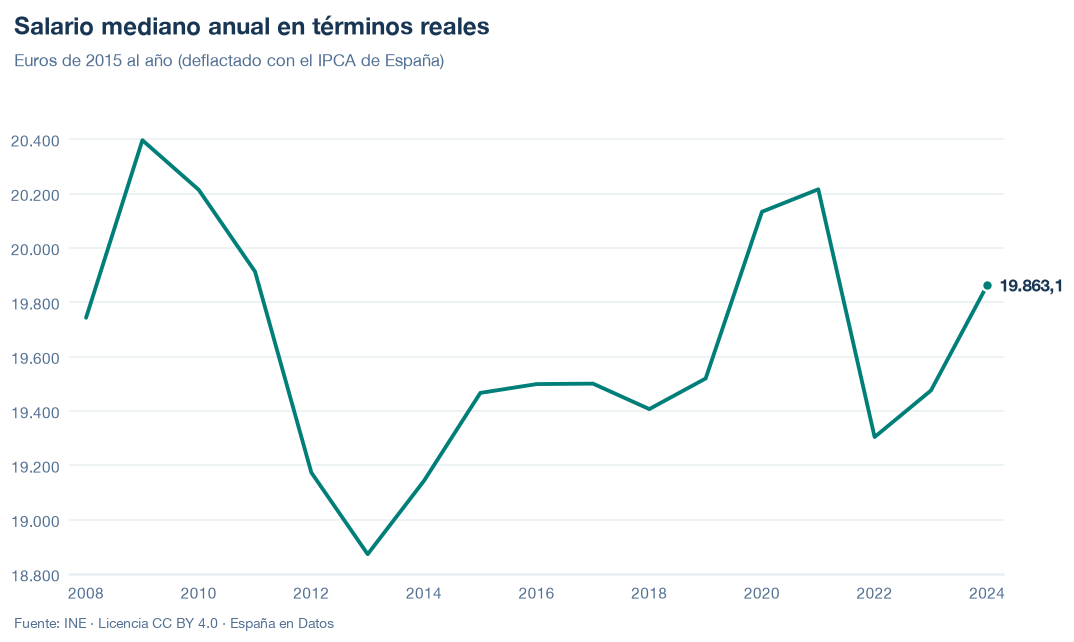

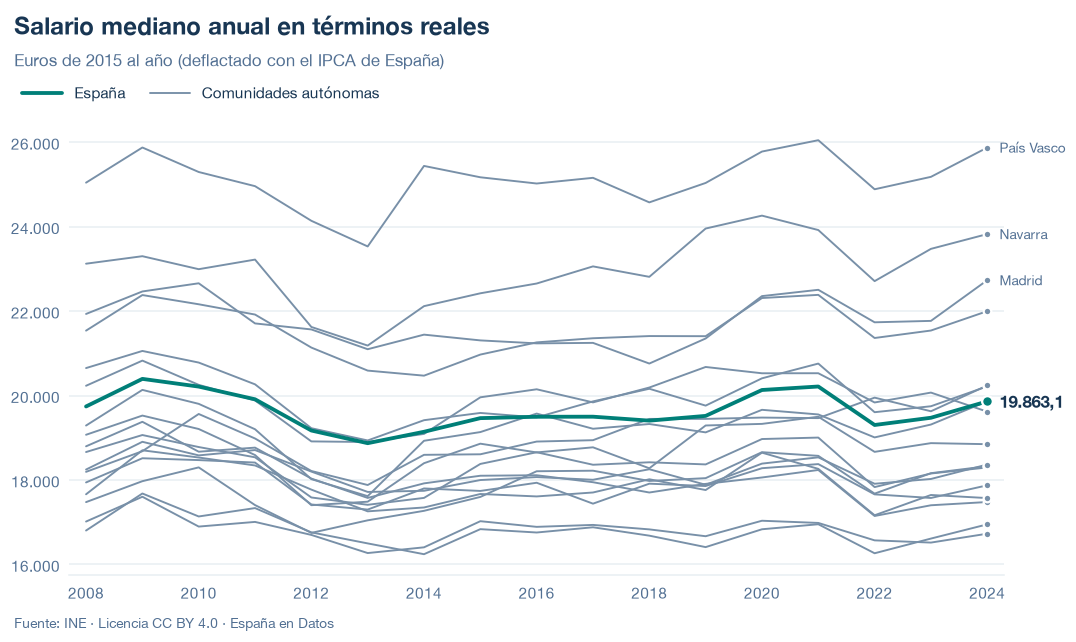

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA, ccaa=vista_ccaa,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)
estilos.mostrar(estilos.figura_ccaa(datos, titulo=TITULO))

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA, ccaa=vista_ccaa,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/salario-mediano-real.json y data/salario-mediano-real.csv


## 6. Fuentes, notas y licencia

- INE, Encuesta Anual de Estructura Salarial, tabla 28191: series `EAES738` (mediana, total nacional), `EAES741` (media, solo para las notas) y la mediana de cada comunidad autónoma.
- Eurostat, `prc_hicp_aind` (`CP00`, `INX_A_AVG`, `ES`).

La fecha de consulta de cada serie está en `fuentes` del JSON.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.